# Lecture 2 companion — whole robots, payload modules, and machine order
**Instructor demonstration: about 20 minutes**, with a 5-minute nonlinear extension. We use tiny models so a class can check the solver's claims by hand.

Run from the top. Prerequisites: Python functions and lecture 1's variables, objectives, and constraints. Install once if needed: `python -m pip install "pulp>=3.3,<4" numpy scipy matplotlib pandas ipywidgets jupyterlab`. All data are deterministic teaching examples. There are no external files or solver services. Widgets are optional; direct function calls produce the same experiments.

[Lab 3](https://github.com/AdoHaha/automation_robotics_lab/blob/master/lab_auto_3.ipynb) develops integer cutting-pattern models in PuLP. [Lab 4](https://github.com/AdoHaha/automation_robotics_lab/blob/master/lab_auto_4.ipynb) builds a general robot-cell scheduler. This companion explains LP bounds, DP states, and the tiny scheduling proof before those larger exercises. Alignment checked at lab commit `3c1b7a70f5990d7665b11a7a853eaf1061a36d30`.

Linear and integer models use **PuLP 3.x with CBC**, as in the labs. The optional nonlinear extension uses SciPy because its quadratic objective is outside PuLP's linear modeling scope.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pulp
from IPython.display import display
from itertools import product
from scipy.optimize import minimize_scalar  # Optional nonlinear extension only.

SOLVER = pulp.PULP_CBC_CMD(msg=False)
assert SOLVER.available(), 'CBC is unavailable; check the PuLP 3.x installation.'
print(f'PuLP {pulp.__version__}; CBC is available')
np.set_printoptions(precision=4, suppress=True)


PuLP 3.3.2; CBC is available


## 1. Why rounding can lose money
Choose whole numbers $x,y$ of robot configurations. Contribution is $3x+2y$, subject to $2x+y\le4$ and $x+2y\le4$, with nonnegative variables. The two rows represent power and floor-space budgets of 4 units each: type x consumes (2,1), and type y consumes (1,2).

**Predict:** solve the two boundary equations. What happens if you round each result down? Can a different integer choice do better?

For maximization, the LP relaxation gives an **upper bound** on integer contribution. Any feasible integer plan gives a **lower bound**. A bound is a statement about the best achievable value, not necessarily a usable plan.

In [2]:
def solve_robot_mix(whole_units=False):
    model = pulp.LpProblem('Robot_configurations', pulp.LpMaximize)
    category = pulp.LpInteger if whole_units else pulp.LpContinuous
    x = pulp.LpVariable('type_x_robots', lowBound=0, cat=category)
    y = pulp.LpVariable('type_y_robots', lowBound=0, cat=category)
    model += 3*x + 2*y, 'shift_contribution'
    model += 2*x + y <= 4, 'assembly_capacity'
    model += x + 2*y <= 4, 'testing_capacity'
    model.solve(SOLVER)
    return model, (x, y)

lp, lp_variables = solve_robot_mix(whole_units=False)
ip, ip_variables = solve_robot_mix(whole_units=True)
assert lp.status == ip.status == pulp.LpStatusOptimal
lp_plan = np.array([v.value() for v in lp_variables])
ip_plan = np.array([v.value() for v in ip_variables])
R = np.array([[2., 1.], [1., 2.]])  # Independent feasibility checks.
profits = np.array([3., 2.])
rounded = np.floor(lp_plan)
# Enumerate independently: there are only nine candidate integer plans.
feasible = [np.array(z) for z in product(range(3), repeat=2) if np.all(R @ z <= 4)]
best = max(feasible, key=lambda z: profits @ z)
assert np.allclose(lp_plan, [4/3, 4/3])
assert np.isclose(pulp.value(ip.objective), 6) and np.array_equal(best, [2, 0])
assert np.allclose(ip_plan, best) and np.all(R @ ip_plan <= 4 + 1e-8)
assert profits @ rounded == 5 and np.isclose(pulp.value(lp.objective), 20/3)
display(pd.DataFrame({'x': [lp_plan[0], rounded[0], ip_plan[0]],
                      'y': [lp_plan[1], rounded[1], ip_plan[1]],
                      'contribution': [pulp.value(lp.objective), profits @ rounded, pulp.value(ip.objective)]},
                     index=['LP bound', 'Round down', 'Integer optimum']))


,x,y,contribution
LP bound,1.333333,1.333333,6.666666
Round down,1.000000,1.000000,5.000000
Integer optimum,2.000000,0.000000,6.000000


**Interpretation:** rounding down yields 5, while choosing two type-$x$ robots yields 6. The LP bound is $6\frac{2}{3}$. Branching on $x\le1$ versus $x\ge2$ covers all integer plans and removes the fractional LP point. Real solvers combine such branching with stronger bounds and cuts.

## 2. A mobile robot's payload: a DP state needs a precise meaning
Four optional inspection modules have weights `[2,3,4,5]` kg and scores `[3,4,5,6]`. Each can be installed **once**. Capacity is 10 kg.

Let $f_k(w)$ be the best score using the **first $k$ modules with weight at most $w$**. Here $w$ is a capacity budget, not the exact weight already used.

$$f_k(w)=\max\{f_{k-1}(w),\ v_k+f_{k-1}(w-w_k)\}$$
The include option exists only if $w\ge w_k$, and $f_0(w)=0$.

**Predict:** at $(k,w)=(4,10)$, compare excluding module 4 with including it and using the best plan for the remaining 5 kg.

In [3]:
weights = np.array([2, 3, 4, 5], dtype=int)
scores = np.array([3, 4, 5, 6], dtype=int)

def knapsack(capacity=10):
    table = np.zeros((len(weights)+1, capacity+1), dtype=int)
    for k, (weight, score) in enumerate(zip(weights, scores), start=1):
        for w in range(capacity+1):
            table[k, w] = table[k-1, w]
            if w >= weight:
                table[k, w] = max(table[k, w], score + table[k-1, w-weight])
    chosen, w = [], capacity
    for k in range(len(weights), 0, -1):
        # On a tie, skip this module: another optimum may exist.
        if table[k, w] > table[k-1, w]:
            chosen.append(k-1)
            w -= weights[k-1]
    return table, sorted(chosen)

def payload_experiment(capacity=10):
    table, chosen = knapsack(int(capacity))
    display(pd.DataFrame(table, index=['No modules', 'First 1', 'First 2', 'First 3', 'First 4']))
    print('Column = kg capacity budget. Selected modules:', [i+1 for i in chosen])
    print('Weight:', weights[chosen].sum(), 'kg; score:', table[-1, -1])
    return table, chosen

table, chosen = payload_experiment(10)
assert chosen == [0, 1, 3] and table[-1, -1] == 13
# Independently enumerate every subset, at every displayed capacity.
subsets = np.array(list(product([0, 1], repeat=4)))
for capacity in range(11):
    admissible = subsets[(subsets @ weights) <= capacity]
    assert table[-1, capacity] == np.max(admissible @ scores)
assert np.all(table[:, 1:] >= table[:, :-1])


,0,1,2,3,4,5,6,7,8,9,10
No modules,0,0,0,0,0,0,0,0,0,0,0
First 1,0,0,3,3,3,3,3,3,3,3,3
First 2,0,0,3,4,4,7,7,7,7,7,7
First 3,0,0,3,4,5,7,8,9,9,12,12
First 4,0,0,3,4,5,7,8,9,10,12,13


Column = kg capacity budget. Selected modules: [1, 2, 4]
Weight: 10 kg; score: 13


**Interpretation:** excluding module 4 gives $f_3(10)=12$. Including it gives $6+f_3(5)=13$. The best plan uses modules 1, 2 and 4 with exactly 10 kg.

**Predict:** reduce capacity to 9 kg. Does the plan simply lose the last chosen module? Explain the new combination. DP is exact here and takes $O(nW)$ work for integer capacity $W$. This is pseudopolynomial: a very large numeric capacity makes a very wide table.

In [4]:
_ = payload_experiment(9)  # Direct-call fallback.
try:
    import ipywidgets as widgets
except ImportError:
    print('Widgets unavailable; change capacity in payload_experiment(capacity=9).')
else:
    display(widgets.interactive(payload_experiment,
        capacity=widgets.IntSlider(value=10, min=0, max=14, step=1,
                                   description='Payload kg', continuous_update=False)))


,0,1,2,3,4,5,6,7,8,9
No modules,0,0,0,0,0,0,0,0,0,0
First 1,0,0,3,3,3,3,3,3,3,3
First 2,0,0,3,4,4,7,7,7,7,7
First 3,0,0,3,4,5,7,8,9,9,12
First 4,0,0,3,4,5,7,8,9,10,12


Column = kg capacity budget. Selected modules: [1, 2, 3]
Weight: 9 kg; score: 12


interactive(children=(IntSlider(value=10, continuous_update=False, description='Payload kg', max=14), Output()…

## 3. Machine order changes the schedule
The lecture's tiny robot cell has two jobs:

- Job 0: M0 for 5 min, then M1 for 6 min.
- Job 1: M1 for 4 min, then M0 for 7 min.

Start times are continuous. Each machine serves one operation at a time. Operations cannot split. There are no setup times or release dates.

**Predict:** can the first operations start together? Draw a feasible schedule. M0 has $5+7=12$ minutes of work, so makespan cannot be below 12. Can your schedule attain that bound?

We enumerate the four possible machine-order pairs, then solve a tiny LP for start times in each branch. This exposes the binary decision without requiring a general scheduler.

The PuLP model below implements the lecture's binary no-overlap formulation. `before['M0'] = 1` means Job 0 precedes Job 1 on M0. A serial schedule gives the horizon $H=5+6+4+7=22$, which bounds the makespan and supplies a valid Big-M. When a processing time changes, the code recomputes $H$.

**Predict:** which two machine orders will the solver choose? Then compare its answer with all four fixed-order cases. The fixed-order checks make the discrete choices visible; the primary model chooses the binary orders itself.

In [5]:
def solve_job_shop(job0_m1=6., fixed_order=None):
    duration = {'J0_M0': 5., 'J0_M1': float(job0_m1), 'J1_M1': 4., 'J1_M0': 7.}
    assert all(d > 0 for d in duration.values())
    horizon = sum(duration.values())  # A feasible serial schedule; valid Big-M.
    model = pulp.LpProblem('Two_job_robot_cell', pulp.LpMinimize)
    start = {op: pulp.LpVariable('start_'+op, lowBound=0) for op in duration}
    before = {m: pulp.LpVariable('J0_before_J1_'+m, cat=pulp.LpBinary) for m in ['M0', 'M1']}
    makespan = pulp.LpVariable('makespan_minutes', lowBound=0, upBound=horizon)
    model += makespan, 'finish_last_job'
    model += start['J0_M1'] >= start['J0_M0'] + duration['J0_M0'], 'job_0_route'
    model += start['J1_M0'] >= start['J1_M1'] + duration['J1_M1'], 'job_1_route'
    for machine, (a, b) in {'M0': ('J0_M0', 'J1_M0'), 'M1': ('J0_M1', 'J1_M1')}.items():
        model += start[b] >= start[a] + duration[a] - horizon*(1-before[machine]), machine+'_J0_first'
        model += start[a] >= start[b] + duration[b] - horizon*before[machine], machine+'_J1_first'
    for op in duration:
        model += makespan >= start[op] + duration[op], 'completion_'+op
    if fixed_order is not None:
        for machine, choice in zip(['M0', 'M1'], fixed_order):
            model += before[machine] == choice, 'fixed_order_'+machine
    model.solve(SOLVER)
    return {'model': model, 'start': start, 'duration': duration,
            'makespan': makespan, 'before': before}


,M0: J0 first,M1: J0 first,status,makespan min
0,0,0,Optimal,22.0
1,0,1,Infeasible,NaN
2,1,0,Optimal,12.0
3,1,1,Optimal,22.0


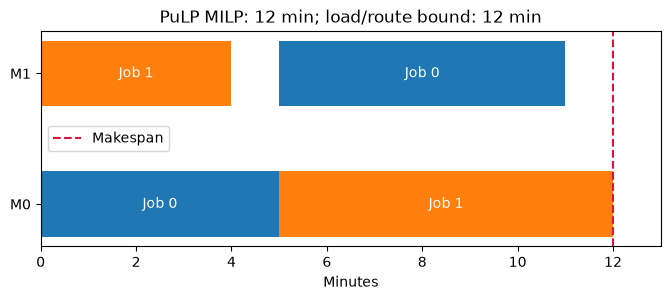

In [6]:
def schedule_experiment(job0_m1=6.):
    best = solve_job_shop(job0_m1)
    assert best['model'].status == pulp.LpStatusOptimal
    branches = [solve_job_shop(job0_m1, fixed_order=order) for order in product([0, 1], repeat=2)]
    rows = []
    for order, branch in zip(product([0, 1], repeat=2), branches):
        optimal = branch['model'].status == pulp.LpStatusOptimal
        rows.append({'M0: J0 first': order[0], 'M1: J0 first': order[1],
                     'status': pulp.LpStatus[branch['model'].status],
                     'makespan min': branch['makespan'].value() if optimal else np.nan})
    display(pd.DataFrame(rows))
    finish = best['makespan'].value()
    starts = {op: variable.value() for op, variable in best['start'].items()}
    duration = best['duration']
    # Independent physical checks, beyond trusting the solver status or the picture.
    for earlier, later in [('J0_M0', 'J0_M1'), ('J1_M1', 'J1_M0')]:
        assert starts[later] + 1e-7 >= starts[earlier] + duration[earlier]
    for a, b in [('J0_M0', 'J1_M0'), ('J0_M1', 'J1_M1')]:
        assert (starts[a]+duration[a] <= starts[b]+1e-7 or
                starts[b]+duration[b] <= starts[a]+1e-7)
    assert np.isclose(finish, max(starts[op]+duration[op] for op in duration))
    assert np.isclose(finish, min(row['makespan min'] for row in rows if row['status']=='Optimal'))
    lower_bound = max(12., job0_m1 + 4., 5. + job0_m1, 11.)
    fig, ax = plt.subplots(figsize=(8, 2.8))
    for op, job, machine in [('J0_M0', 0, 0), ('J0_M1', 0, 1), ('J1_M1', 1, 1), ('J1_M0', 1, 0)]:
        ax.barh(machine, duration[op], left=starts[op], height=.5,
                color=['tab:blue', 'tab:orange'][job])
        ax.text(starts[op]+duration[op]/2, machine, f'Job {job}', ha='center', va='center', color='white')
    ax.axvline(finish, color='crimson', linestyle='--', label='Makespan')
    ax.set(yticks=[0, 1], yticklabels=['M0', 'M1'], xlabel='Minutes',
           xlim=(0, finish+1), title=f'PuLP MILP: {finish:g} min; load/route bound: {lower_bound:g} min')
    ax.legend(); plt.show()
    best['branches'] = branches
    return best

best = schedule_experiment()
assert tuple(round(best['before'][m].value()) for m in ['M0', 'M1']) == (1, 0)
assert np.isclose(best['makespan'].value(), 12.)
assert sum(b['model'].status == pulp.LpStatusInfeasible for b in best['branches']) == 1
# Faster M1 processing cannot evade M0's 12-minute workload.
faster = solve_job_shop(5)
assert faster['model'].status == pulp.LpStatusOptimal
assert np.isclose(faster['makespan'].value(), 12)


**Interpretation:** run Job 0 on M0 during `[0,5)` and Job 1 on M1 during `[0,4)`. Then Job 1 uses M0 during `[5,12)` and Job 0 uses M1 during `[5,11)`. Makespan is 12. Feasibility plus a matching lower bound proves optimality.

The lab warm-up uses the same two routes before introducing its general scheduling model.

**Predict:** reduce Job 0's M1 duration to 5. Will makespan improve? Then increase it to 8. Which workload or job-route bound changes?

,M0: J0 first,M1: J0 first,status,makespan min
0,0,0,Optimal,24.0
1,0,1,Infeasible,NaN
2,1,0,Optimal,13.0
3,1,1,Optimal,24.0


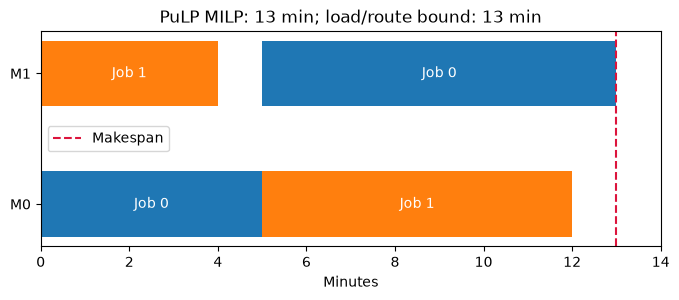

interactive(children=(IntSlider(value=6, continuous_update=False, description='J0 M1 min', max=12, min=3), Out…

In [7]:
# Every interactive setting runs the same validation checks.
_ = schedule_experiment(job0_m1=8)
if 'widgets' in globals():
    display(widgets.interactive(schedule_experiment,
        job0_m1=widgets.IntSlider(value=6, min=3, max=12, step=1,
                                 description='J0 M1 min', continuous_update=False)))


## 4. Optional nonlinear extension: a global optimum needs a reason
Let output be continuous, price $P(x)=100-2x$, cost $20x+100$, and capacity $0\le x\le30$. Then profit is $80x-2x^2-100$.

**Predict:** use $\Pi'(x)=80-4x$ to find the stationary point. Since $\Pi''(x)=-4$, profit is strictly concave; a feasible stationary point is the unique global maximum. If capacity falls to 15, which boundary becomes optimal?

A downward-sloping demand curve does not mean demand is elastic everywhere. Nonlinear also does not automatically mean nonconvex or intractable.

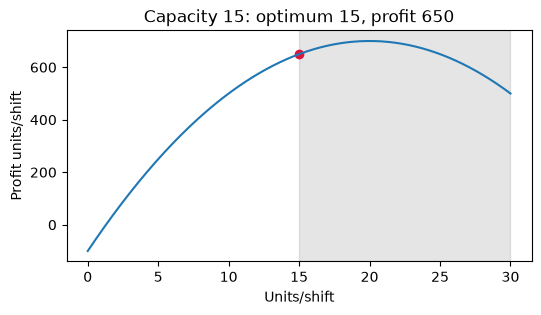

In [8]:
def profit(x):
    return 80*x - 2*x*x - 100

def profit_experiment(capacity=30):
    result = minimize_scalar(lambda x: -profit(x), bounds=(0, capacity), method='bounded')
    assert result.success
    exact_x = min(20., float(capacity))
    assert np.isclose(result.x, exact_x, atol=1e-3)
    grid = np.linspace(0, 30, 250)
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.plot(grid, profit(grid)); ax.axvspan(capacity, 30, color='gray', alpha=.2)
    ax.scatter(exact_x, profit(exact_x), color='crimson')
    ax.set(xlabel='Units/shift', ylabel='Profit units/shift', title=f'Capacity {capacity}: optimum {exact_x:g}, profit {profit(exact_x):g}')
    plt.show()
    return result

assert profit(20) == 700 and profit(15) == 650
_ = profit_experiment(15)


## Exit ticket
1. Why does an LP bound remain useful when the fractional plan cannot be implemented?
2. What would change in the knapsack recurrence if each module could be used repeatedly?
3. Does a beautiful Gantt chart prove feasibility? What checks and lower bound did we use?
4. Explain why faster processing at one station can leave overall completion time unchanged.

**Sources:** mathematical data follow `lecture_2.tex`; robot-count example is an explicit teaching addition. Linear/integer modeling uses [PuLP 3.3](https://github.com/coin-or/pulp/tree/3.3.0) and its CBC interface. The nonlinear extension follows [SciPy `minimize_scalar`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize_scalar.html).